# Stock risk report
inmeng Pan · HW2

Real observations from the supplied homework database, using `ohlc_hw_cleaned`.
Requested and actual observation coverage are shown separately. Adjusted close drives
report returns and drawdown; missing sessions relative to this ticker's reference
`ohlc` keys are retained as NaN. Source histories ending early are not extrapolated.


In [1]:
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/zhexi/Desktop/dai/146/HW2_original/inmeng_Pan/data/data.db"


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, JSON
from analysis import (load_stock, calculate_returns, calculate_volatility,
    calculate_max_drawdown, calculate_sharpe_ratio, stock_metrics, plot_stock, report_series)

data = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(data)} trading days")
print(f"Actual observations: {data.ts.min().date()} to {data.ts.max().date()}")
if len(data) < 21:
    print("Insufficient history for 20-return rolling volatility: at least 21 prices required.")
if len(data) < 50:
    print("Insufficient history for the 50-price moving average.")
display(data.head(), data.tail())

prices, daily_returns, rolling_volatility, drawdown = report_series(data)
print("Calendar sessions:", len(prices), "| Missing observations:", int(prices.isna().sum()),
      "| Valid one-session returns:", int(daily_returns.notna().sum()))
if prices.isna().any():
    print("Gaps remain missing. Gap-spanning price moves are excluded from daily statistics.")


IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29


,ts,open,high,low,close,adj_close,volume,ticker,original_ticker,filled_open,filled_high,filled_low,filled_close,volume_unknown,adjustment_rebuilt,return_outlier,outlier_review
0,2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100,IBM,IBM,0,0,0,0,0,0,0,
1,2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203,IBM,IBM,0,0,0,0,0,0,0,
2,2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400,IBM,IBM,0,0,0,0,0,0,0,
3,2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263,IBM,IBM,0,0,0,0,0,0,0,
4,2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500,IBM,IBM,0,0,0,0,0,0,0,


,ts,open,high,low,close,adj_close,volume,ticker,original_ticker,filled_open,filled_high,filled_low,filled_close,volume_unknown,adjustment_rebuilt,return_outlier,outlier_review
121,2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740,IBM,IBM,0,0,0,0,0,0,0,
122,2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300,IBM,IBM,0,0,0,0,0,0,0,
123,2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543,IBM,IBM,0,0,0,0,0,0,0,
124,2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121,IBM,IBM,0,0,0,0,0,0,0,
125,2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300,IBM,IBM,0,0,0,0,0,0,0,


Calendar sessions: 126 | Missing observations: 0 | Valid one-session returns: 125


## Daily risk series
Log returns drive volatility, Sharpe and daily summary statistics. Rolling volatility
uses 20 nonmissing returns and the sample standard deviation; warm-up values remain
missing. Drawdown can recover, while its minimum is the maximum loss from a prior peak.
The 2% risk-free rate is the assignment's annual Sharpe approximation.


Internal calendar gaps remain NaN. Only returns between adjacent supplied sessions enter daily statistics. Drawdown uses observed peaks and may miss an unobserved intragap loss.


,ts,adj_close,log_return,rolling_volatility,drawdown
121,2024-11-22,222.97,0.002560,0.241515,-0.044769
122,2024-11-25,226.13,0.014073,0.241623,-0.031231
123,2024-11-26,228.83,0.011869,0.236457,-0.019664
124,2024-11-27,226.92,-0.008382,0.212190,-0.027847
125,2024-11-29,227.41,0.002157,0.212125,-0.025748


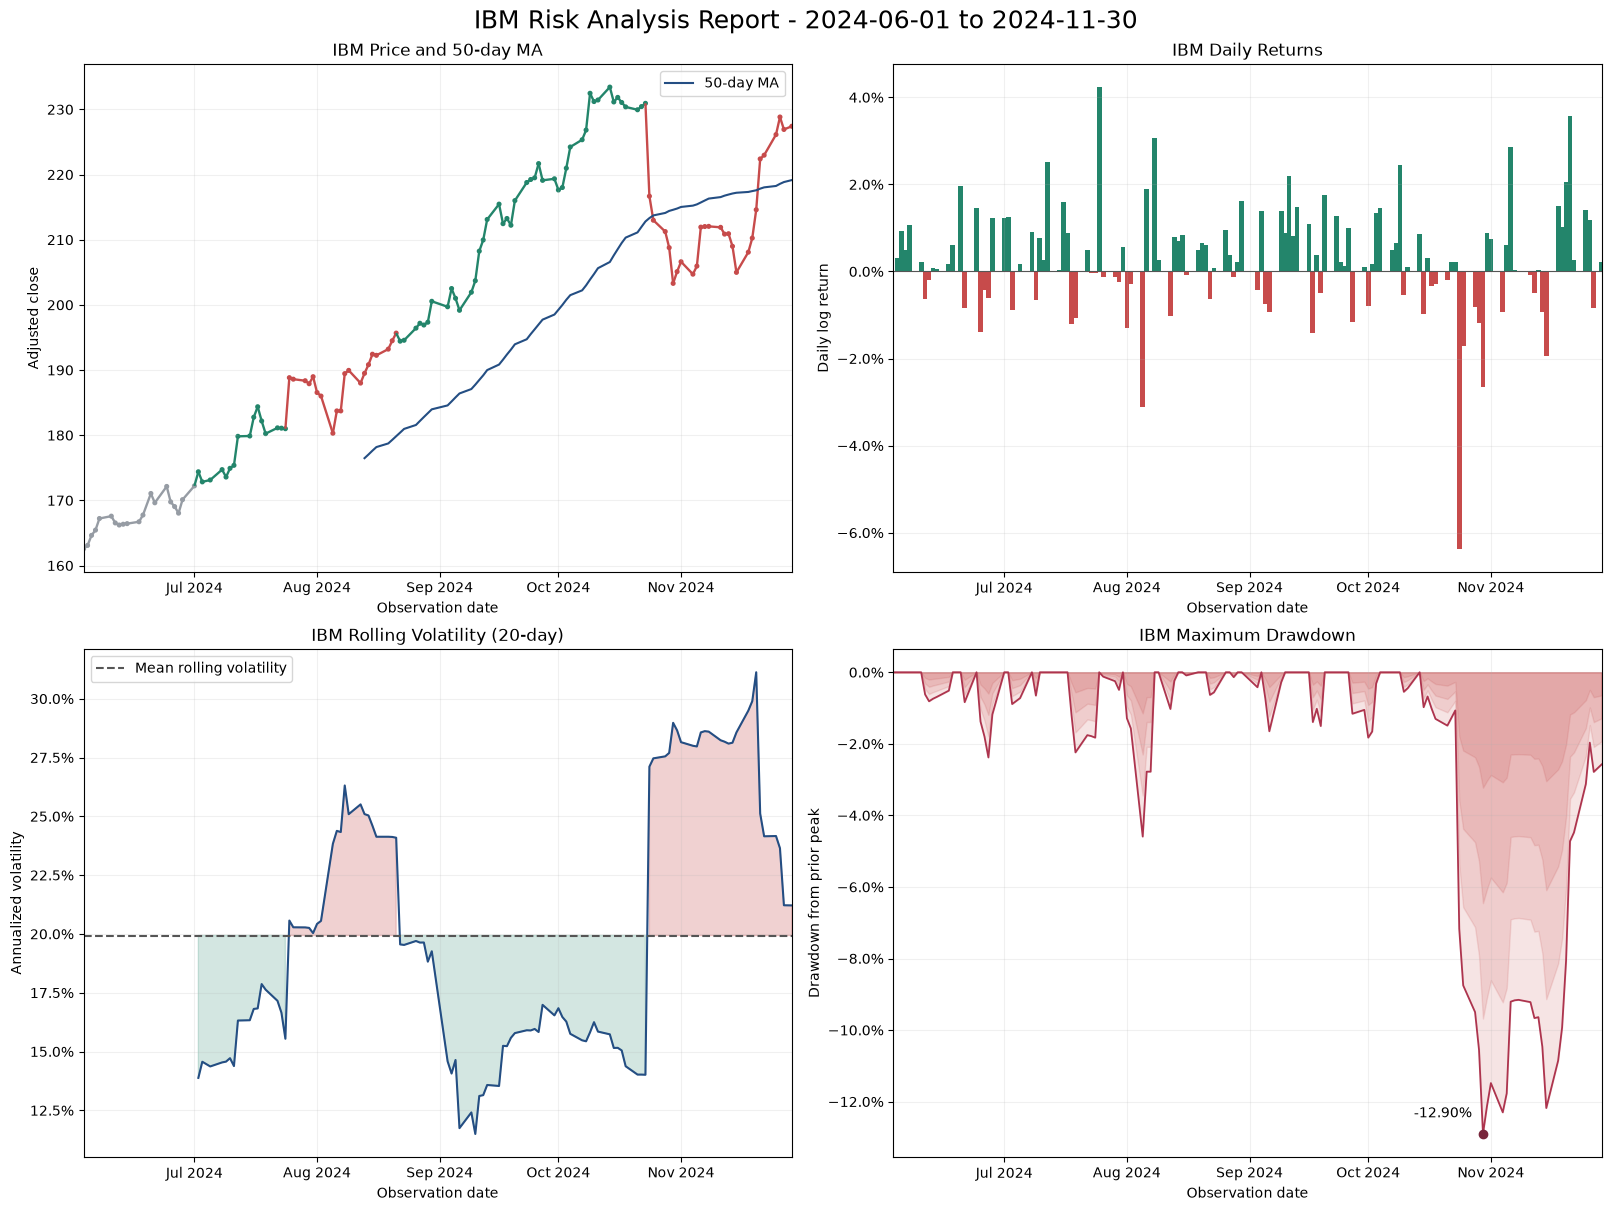

In [4]:
data["log_return"] = data.ts.map(daily_returns)
data["rolling_volatility"] = data.ts.map(rolling_volatility)
data["drawdown"] = data.ts.map(drawdown)
display(data[["ts", "adj_close", "log_return", "rolling_volatility", "drawdown"]].tail())
fig = plot_stock(data, ticker, start_date, end_date)
display(fig)
plt.close(fig)


## Summary
Percentages are formatting only; the exported metrics remain fractions. Annualized
return compounds the observed log returns at 252 periods per year. Whole-period
volatility differs from the batch comparison's mean rolling volatility. Positive days
include zero-return days in the denominator. Undefined estimates display as N/A.


With missing sessions, annualized return summarizes available one-session returns, whereas total return uses the first/last observed prices. They need not compound to the same result. Neither gap returns nor zero returns are invented.


In [5]:
report_metrics = stock_metrics(data)
rows = [
    ("Total Return", "total_return"), ("Annualized Return", "annualized_return"),
    ("Annualized Volatility", "annualized_volatility"), ("Sharpe Ratio", "sharpe_ratio"),
    ("Maximum Drawdown", "max_drawdown"), ("Best Day", "best_day"),
    ("Worst Day", "worst_day"), ("Positive Days", "positive_days"),
    ("Average Up Day", "average_up_day"), ("Average Down Day", "average_down_day")]
formatted = []
for label, key in rows:
    value = report_metrics[key]
    formatted.append((label, "N/A" if pd.isna(value) else f"{value:.2f}" if key == "sharpe_ratio" else f"{value:+.2%}"))
display(pd.DataFrame(formatted, columns=["Metric", "Value"]).set_index("Metric"))
json_metrics = {key: None if isinstance(value, float) and not np.isfinite(value) else value
                for key, value in report_metrics.items()}
display(JSON({"report_metrics": json_metrics}))


,Value
Metric,
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,+20.42%
Sharpe Ratio,3.22
Maximum Drawdown,-12.90%
Best Day,+4.24%
Worst Day,-6.37%
Positive Days,+63.20%
Average Up Day,+0.95%


<IPython.core.display.JSON object>